# 04 · Sentence-BERT advanced model and experiment comparison
Frozen pretrained encoder with a fitted paired-document classifier. No claim of transformer fine-tuning.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import numpy as np
def read_json(path): return json.loads((ROOT/path).read_text())

In [2]:
encoder=read_json('models/encoder_manifest.json')
print(encoder)
experiments=pd.read_csv(ROOT/'reports/experiments/experiments.csv')
display(experiments.sort_values('validation_macro_f1',ascending=False))

{'model': 'sentence-transformers/all-MiniLM-L6-v2', 'revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'dimensions': 384, 'max_sequence_length': 256, 'chunk_words': 150, 'max_chunks': 8, 'fine_tuned_on_capstone': False}


,model,validation_accuracy,validation_macro_f1,training_seconds
3,Sentence-BERT + logistic C1,0.512053,0.473240,3.165
2,Sentence-BERT + logistic C0.1,0.512884,0.473236,1.583
1,Embedding cosine + logistic,0.489609,0.415217,0.031
0,TF-IDF + Random Forest baseline,0.493766,0.391169,NaN
6,Sentence-BERT + RandomForest leaf3,0.506234,0.362616,112.771
5,Sentence-BERT + ExtraTrees leaf5,0.522860,0.354198,39.277
4,Sentence-BERT + ExtraTrees leaf2,0.514547,0.322374,47.866


In [3]:
from resume_matcher.model import ResumeJDMatcher
from resume_matcher.advanced import EmbeddingResumeJDMatcher
from sklearn.base import clone
from sklearn.metrics import classification_report
import joblib
final=ResumeJDMatcher.load(ROOT/'models/resume_matcher.joblib')
train=pd.read_csv(ROOT/'data/processed/train.csv')
validation=pd.read_csv(ROOT/'data/processed/validation.csv')
advanced=EmbeddingResumeJDMatcher(clone(final.classifier))
advanced.embedding_cache=joblib.load(ROOT/'models/document_embeddings.joblib')['embeddings']
advanced.fit(train)
x=advanced._feature_matrix(validation.resume_text,validation.jd_text)
pred=advanced.label_encoder.inverse_transform(advanced.classifier.predict(x))
print(classification_report(validation.label,pred,zero_division=0))
print('Feature dimensions:',x.shape[1])

               precision    recall  f1-score   support

      low_fit       0.61      0.66      0.64       573
potential_fit       0.32      0.33      0.33       305
   strong_fit       0.50      0.42      0.46       325

     accuracy                           0.51      1203
    macro avg       0.48      0.47      0.47      1203
 weighted avg       0.51      0.51      0.51      1203

Feature dimensions: 1545


,accuracy,macro_F1,NDCG@3,Precision@3
majority,0.487209,0.218400,0.498322,0.214741
baseline,0.467311,0.362623,0.614961,0.289617
advanced,0.479250,0.448901,0.691027,0.306011


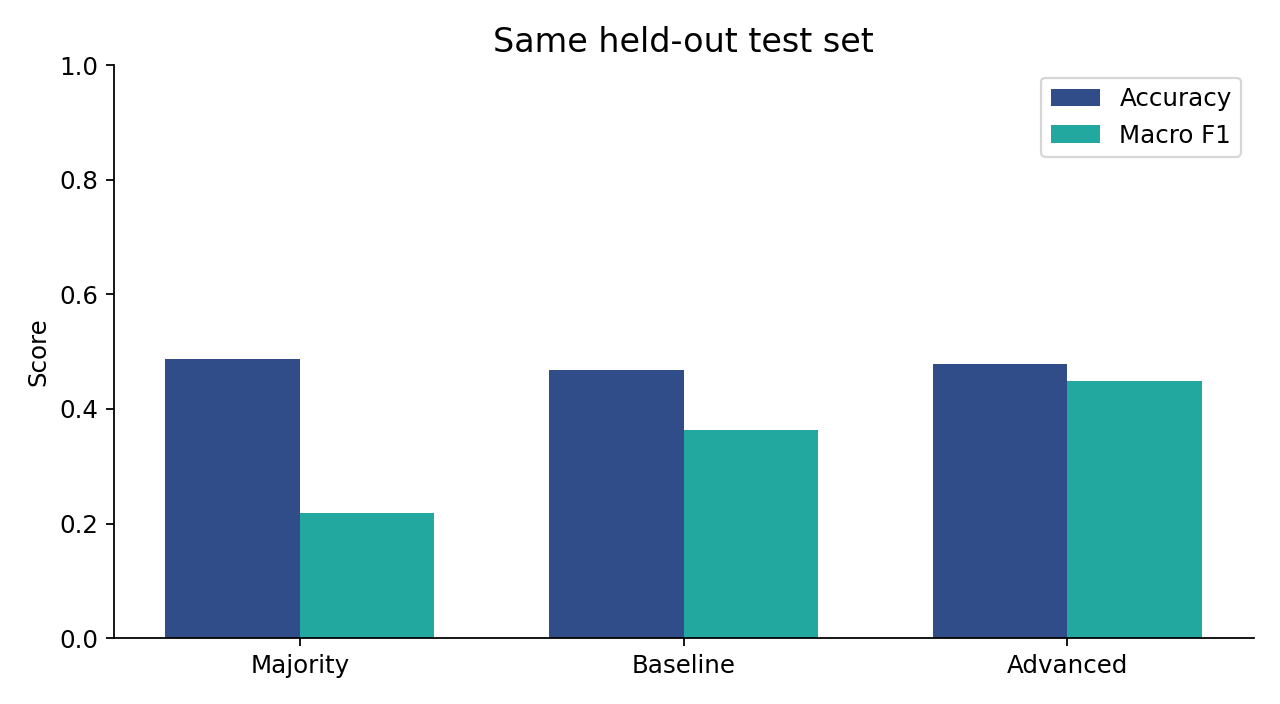

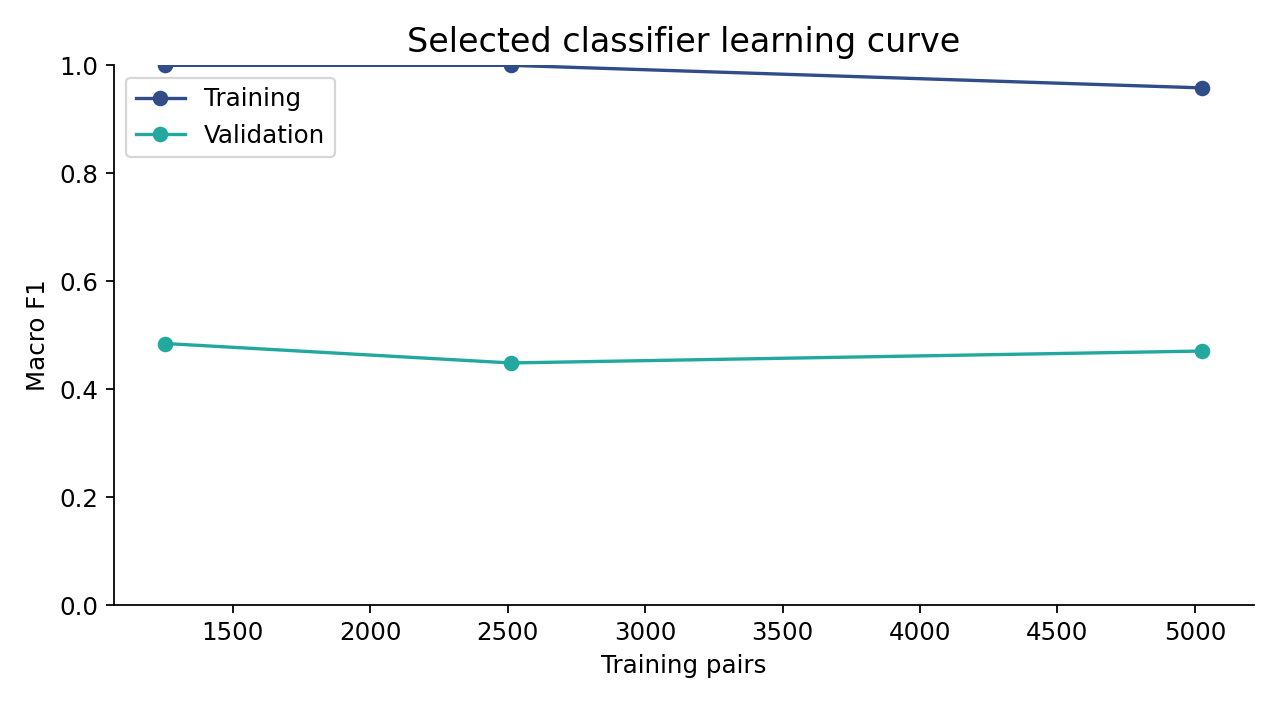

In [4]:
metrics=read_json('reports/metrics.json')
display(pd.DataFrame({name:{'accuracy':m['accuracy'],'macro_F1':m['macro_f1'],'NDCG@3':m['ranking']['ndcg_at_3'],'Precision@3':m['ranking']['precision_at_3_strong_fit']} for name,m in metrics.items()}).T)
from IPython.display import Image
display(Image(filename=str(ROOT/'reports/figures/model_comparison.png')))
display(Image(filename=str(ROOT/'reports/figures/learning_curve.png')))

In [5]:
demo=read_json('data/demo_cases.json')
results=final.rank_candidates(demo['jd_text'],demo['candidates'])
display(pd.DataFrame([{k:r[k] for k in ['candidate_name','predicted_fit','match_score']} for r in results]))
failure=final.predict_one(demo['failure_case']['resume_text'],demo['jd_text'])
print('Known explanation failure:',failure['predicted_fit'],failure['skill_gap']['matched_skills'])
print(read_json('reports/responsible_use_checks.json'))

C:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,candidate_name,predicted_fit,match_score
0,Relevant ML experience,potential_fit,79.92
1,Partial analytics experience,low_fit,32.90
2,Unrelated design experience,potential_fit,20.76


Known explanation failure: potential_fit ['docker', 'machine learning', 'model evaluation', 'nlp', 'python', 'rest api', 'scikit-learn', 'sql']
{'demographic_field_checks': [{'example': 'Relevant ML experience', 'variants': 4, 'invariant': True}, {'example': 'Partial analytics experience', 'variants': 4, 'invariant': True}, {'example': 'Unrelated design experience', 'variants': 4, 'invariant': True}], 'keyword_explanation_checks': [{'resume': 'Python SQL', 'jd': 'Python SQL Docker', 'expected_matched': ['python', 'sql'], 'actual_matched': ['python', 'sql'], 'expected_missing': ['docker'], 'actual_missing': ['docker'], 'passed': True}, {'resume': 'Java Spring Boot', 'jd': 'Java SQL', 'expected_matched': ['java'], 'actual_matched': ['java'], 'expected_missing': ['sql'], 'actual_missing': ['sql'], 'passed': True}, {'resume': 'Excel Power BI', 'jd': 'Excel Power BI Tableau', 'expected_matched': ['excel', 'power bi'], 'actual_matched': ['excel', 'power bi'], 'expected_missing': ['tableau'],

Configuration selection uses validation macro F1. Test metrics report the final refit and do not select a configuration. Ranking relevance is 0/1/2 and Precision@3 counts strong fit. Score probabilities remain uncalibrated. Shared resumes, uncertain label provenance and limited explanation checks constrain business use.